**Hueristic method:**

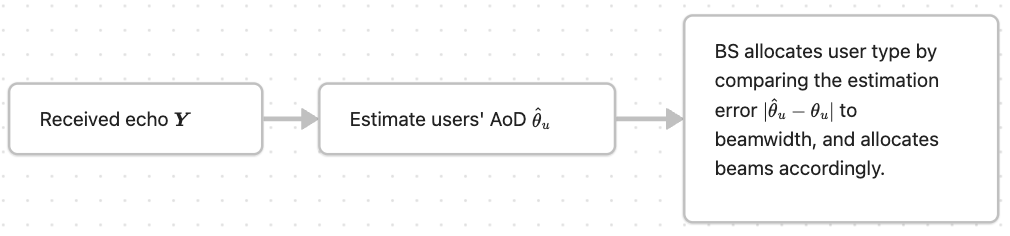

It uses a genie information: the true AoD.

### Reinforcement Learning
**State** $$\mathcal{S} = \left\{[\boldsymbol{b}(t-2), \boldsymbol{b}(t-1), \boldsymbol{b}(t)], [B_1, \cdots, B_U], [\text{Total packets}], [\lambda_1,\cdots, \lambda_U]\right\}$$

where $\boldsymbol{b}_f$ is the averaged beamforming output. $\boldsymbol{b}_u = \mathrm{E}(\boldsymbol{f}_u^H \boldsymbol{Y})$. 

**Action** 
The action space is simplified.
$$a_n = \left\{ [\lambda_1, \cdots, \lambda_U], [\mathcal{C}_1, \cdots, \mathcal{C}_U]\right\}$$
For a single user, the action space is 2.
- $\lambda_u = 1$: the beam $\mathcal{C}_{u, n} = \mathcal{C}_{u, n-1}$, or the beam $\mathcal{C}_{u, n}$ is the beam from the estimation result 

- $\lambda_u = 0$:  $\mathcal{C}_{u, n} = \min(\mathcal{C}_{u, n-1}) + [-1,0, 1]$

The total action space is $2^U$.

**Reward**
$$r = \sum_{u=1}^U(1 + \frac{\text{Transmitted packets}}{\text{Total packets}} )(R_u>4) \lambda_u$$

Training: there are only 6 possible initial user locations 
Testing: users can start from anywhere

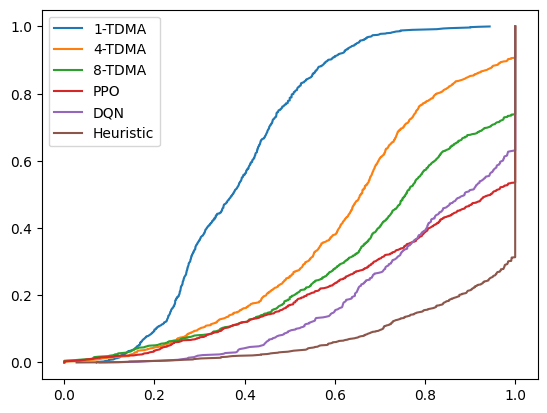

In [18]:
import numpy as np
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
for N in [1,4,8]:
    th = np.loadtxt('Multi-user-BM/results_bm/Thp_' + str(N) + 'TDMA')
    th_cdf = np.sort(th)
    yvals = np.arange(len(th))/float(len(th)-1)
    ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_PPO')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_DQN')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_heuristic')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
ax.legend(['1-TDMA','4-TDMA','8-TDMA', 'PPO', 'DQN', 'Heuristic'])

**X-TDMA** 
$X$-TDMA denotes that the BS assign a sensing slot of every user before every $X$ communication slots. 

In the above figure, users' speed $v\sim\mathcal{N}(20,2)$. 

Users's speed is $v\sim\mathcal{N}(30,2)$. The PPO still uses the model trained from $v\sim\mathcal{N}(20,2)$

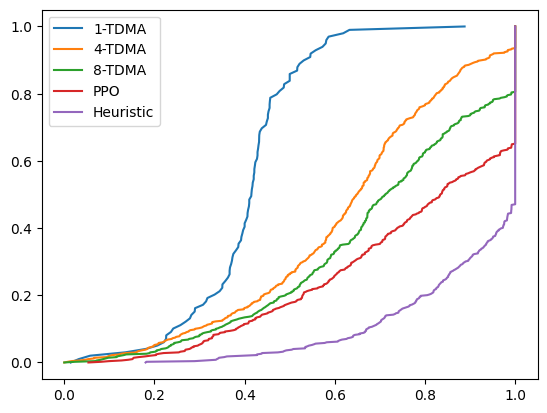

In [16]:
fig, ax = plt.subplots()
for N in [1,4,8]:
    th = np.loadtxt('Multi-user-BM/results_bm/Thp_' + str(N) + 'TDMA_v=30')
    th_cdf = np.sort(th)
    yvals = np.arange(len(th))/float(len(th)-1)
    ax.plot(th_cdf, yvals, '-')

th = np.loadtxt('Multi-user-BM/results_bm/Thp_PPO_v=30')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
th = np.loadtxt('Multi-user-BM/results_bm/Thp_heuristic_v=30')
th_cdf = np.sort(th)
yvals = np.arange(len(th))/float(len(th)-1)
ax.plot(th_cdf, yvals, '-')
ax.legend(['1-TDMA','4-TDMA','8-TDMA', 'PPO','Heuristic'])

The PPO cannot outperform the Heuristic method because the heuristic method uses the true AoD information of the users.

Ways to avoid using true information in the Heuristic method:

- calcuate the Bayesian cramer rao bound. Consider the uniform distribution as prior information for AoD 

- calculate an estimate of CRB considering the previous estimate as mean and CRB as variance

- calculate an estimate of CRB using the previous estimate

TODO:
- check other reward functions 

- check make the action space more complicated

- consider the sensing metric 